<a href="https://colab.research.google.com/github/mvaishnavi2007/ITA0520---CV/blob/main/EXP_25_Watch_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications.efficientnet import (
    EfficientNetB0, preprocess_input, decode_predictions
)

Saving Screenshot 2026-11-11 182531.png to Screenshot 2026-11-11 182531.png


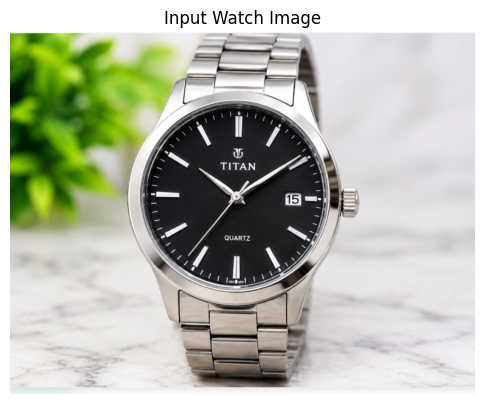

In [4]:
from google.colab import files

uploaded = files.upload()
image_path = list(uploaded.keys())[0]

img = cv2.imread(image_path)

if img is None:
    raise ValueError("Unable to read image")

plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Input Watch Image")
plt.show()

In [5]:
model = EfficientNetB0(weights="imagenet")

print("Object recognition model loaded successfully")

21834768/21834768 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Object recognition model loaded successfully


In [6]:
image = cv2.resize(img, (224, 224))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

image = np.expand_dims(image, axis=0)
image = preprocess_input(image)

predictions = model.predict(image)

results = decode_predictions(predictions, top=5)[0]

print("Object Recognition Results:")

for result in results:
    print(result[1], ":", round(float(result[2]) * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Object Recognition Results:
analog_clock : 57.31 %
stopwatch : 16.73 %
digital_watch : 10.14 %
wall_clock : 1.43 %
magnetic_compass : 1.17 %


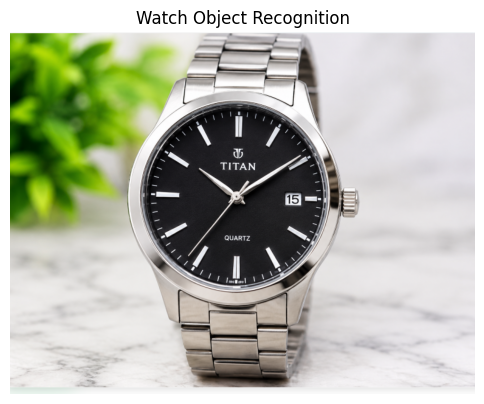

In [7]:
plt.figure(figsize=(6,6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Watch Object Recognition")
plt.show()